# Santander Product Recommendation — what will a bank customer add next month?

The data, target and baseline tables and the error analysis are computed live from the processed Parquet
files (`processed/`) with the functions in `santander/story_analysis.py`. Model results (comparison, ablations, XAI) are
read from files produced by the training scripts (`analysis_output/`). Nothing is retrained here; the notebook runs in
under a minute.

**TL;DR**
- **Task:** for 929,615 customers, rank the bank products they do not hold yet by how likely they are to add each one
  in June 2016. Metric: MAP@7.
- **Result:** a LightGBM multiclass model on 175 leakage-safe features scores about **0.898 MAP@7** (mean of 4
  time-based folds, customers who add ≥1 product). The best non-personalised popularity ranking scores about 0.65.
- **What mattered:** a time-respecting target and validation design, careful data cleaning (several columns are
  frozen or wrong in the first months), and product-history features. Model family mattered little: seven model types
  land within ~0.006 of each other, which is about the size of month-to-month noise.
- **Honest limits:** June seasonality is learned from a single June; the metric ignores customers who add nothing;
  removing sensitive attributes does not remove proxies; the #1 recommendation changes with the random seed alone for
  ~15% of customers.

In [1]:
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

ROOT = "."                                   # run from the project folder
AO = os.path.join(ROOT, "analysis_output")
PROC = os.path.join(ROOT, "processed")
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
def csv(path, **kw): return pd.read_csv(os.path.join(AO, path), **kw)     # model results from the training scripts

from santander import story_analysis as sa              # analysis functions, computed live from processed/*.parquet
panel = sa.load_panel()                  # all 13.6M customer-month rows, product flags only (~0.5 GB)

# feature experiments by run_change.py: variants base / cap / cap+A / cap+B x 4 folds x 2 seeds (MAP@7, MAP@7 on
# "stagnant" customers); used in §5 (seed noise), §7 (capping), §8 (experiment log) and §10 (stagnant customers)
change_exp = csv("models/change_experiments.csv")

# model comparison by train_compare_models.py etc.: MAP@7 per fold (+ mean / std rows) for each algorithm on the
# earlier 166-feature set, mostly default settings; used in §5 (month-to-month spread) and §9
model_cmp = csv("model_comparison.csv", index_col=0)

## 1. Problem and metric
Monthly snapshots (2015-01-28 … 2016-05-28) list, for each customer, which of 24 products they hold. The test file is
the customer list for 2016-06-28 **without** the product columns. A product is *added* when it is held in June but not
in May. Each customer gets up to 7 products not held in May, ranked.

**MAP@7** rewards putting the products that were really added near the top. Kaggle averages over *all* test customers
(those who add nothing score 0), so its leaderboard numbers are small (about our score × the ~3.5% share of adders).
We compute MAP@7 **only over customers who add at least one product**: same ranking quality, different denominator.
That also means every customer always gets a list — there is no "will not add" option.

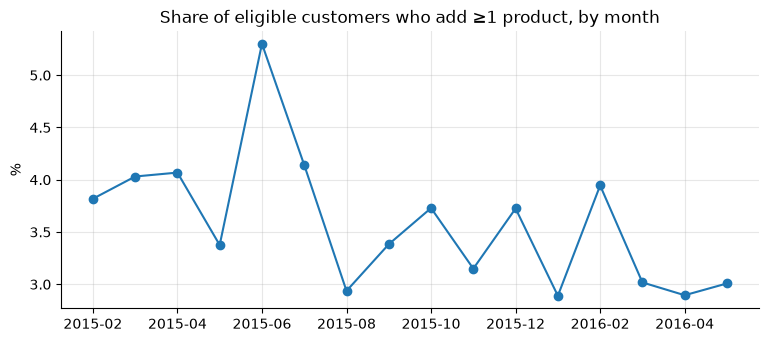

mean 3.59%  (max 5.30% in 2015-06)


In [2]:
tm, adds_by_product = sa.target_summary(panel)
ax = tm["share_customers_with_add_%"].plot(marker="o", title="Share of eligible customers who add ≥1 product, by month")
ax.set_ylabel("%"); plt.show()
print(f"mean {tm['share_customers_with_add_%'].mean():.2f}%  (max {tm['share_customers_with_add_%'].max():.2f}% in "
      f"{tm['share_customers_with_add_%'].idxmax()})")

## 2. The data at a glance
One row per customer per month. The cell below reads numbers straight from the cleaned Parquet file
(2.3 GB CSV → ~190 MB Parquet; columns renamed to English with `santander/column_map.py`).

train rows 13,647,309 | columns 51 | months 17 | test customers 929,615


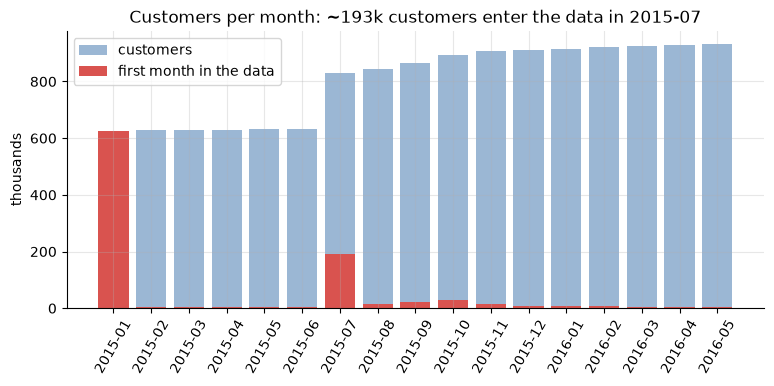

,ids first seen,tenure <= 1 month %,median tenure (months)
2015-01,625457,1.0,55.0
2015-02,4468,73.2,0.0
2015-03,3976,73.9,0.0
2015-04,3423,73.6,0.0
2015-05,3501,76.6,0.0
2015-06,3217,76.0,0.0
2015-07,193115,9.4,53.0
2015-08,14799,98.1,0.0
2015-09,23598,98.5,0.0
2015-10,28495,98.6,0.0


In [3]:
meta = pq.ParquetFile(os.path.join(PROC, "train_clean.parquet")).metadata
cpm = sa.customers_per_month(panel)
print(f"train rows {meta.num_rows:,} | columns {meta.num_columns} | months {len(cpm)} | "
      f"test customers {pq.ParquetFile(os.path.join(PROC, 'test_clean.parquet')).metadata.num_rows:,}")
fig, ax = plt.subplots()
ax.bar(cpm.index, cpm["customers"] / 1e3, color="#9bb7d4", label="customers")
ax.bar(cpm.index, cpm["first_seen_this_month"] / 1e3, color="#d9534f", label="first month in the data")
ax.set_ylabel("thousands"); ax.set_title("Customers per month: ~193k customers enter the data in 2015-07")
ax.legend(); plt.xticks(rotation=60); plt.show()

# "First month in the data" is not "new to the bank": tenure (months since first contract) in each ID's first month
sa.first_month_tenure().round(1)

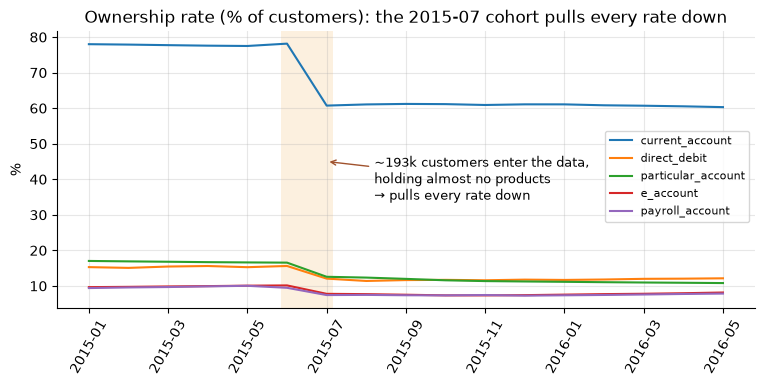

In [4]:
own = sa.ownership_rate_by_month(panel)
ax = own.loc[["current_account", "direct_debit", "particular_account", "e_account", "payroll_account"]].T.plot(
    title="Ownership rate (% of customers): the 2015-07 cohort pulls every rate down")
# highlight the 2015-06 -> 2015-07 step (x positions are 0..16 = month index)
x0, x1 = list(own.columns).index("2015-06"), list(own.columns).index("2015-07")
ax.axvspan(x0 - 0.15, x1 + 0.15, color="#f0ad4e", alpha=0.18, lw=0)
n_new = cpm.loc["2015-07", "first_seen_this_month"]
ax.annotate(f"~{n_new / 1e3:.0f}k customers enter the data,\nholding almost no products\n→ pulls every rate down",
            xy=(x1, 45), xytext=(x1 + 1.2, 40), fontsize=9, va="center",
            arrowprops=dict(arrowstyle="->", color="#a0522d"))
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.66), fontsize=8)
ax.set_ylabel("%"); plt.xticks(rotation=60); plt.show()

## 3. Data quality: what is wrong, and what we did about it
Principle: **keep the raw column, add a corrected column next to it, never back-fill** (filling a missing value from a
later month would leak the future into training rows).

**3a. Profile columns are frozen for the first seven months.** For the same customer, every non-product column is
unchanged from 2015-01 to 2015-07 and starts moving in 2015-08. Our interpretation (not stated in the data): those
months carry a copy of the profile from around 2015-07. Rows from months 0–6 get a `demographics_stale` flag.
Section 3b shows why we think the copy is from 2015-07 and not a January value held still: in 2015-01 the raw
seniority is exactly 6 months ahead of the seniority implied by the contract date, 5 months in 2015-02, … 0 in 2015-07.

If this reading is right, the raw data itself carries ~2015-07 profile values into earlier months (a small leak of the
future that was already in the data, not added by us). It does not touch the validation scores (folds are months
13–16), but early training rows see a slightly "future" profile; the flag lets the model discount them, and the
profile-lag features (set B) use months ≥ 7 only.

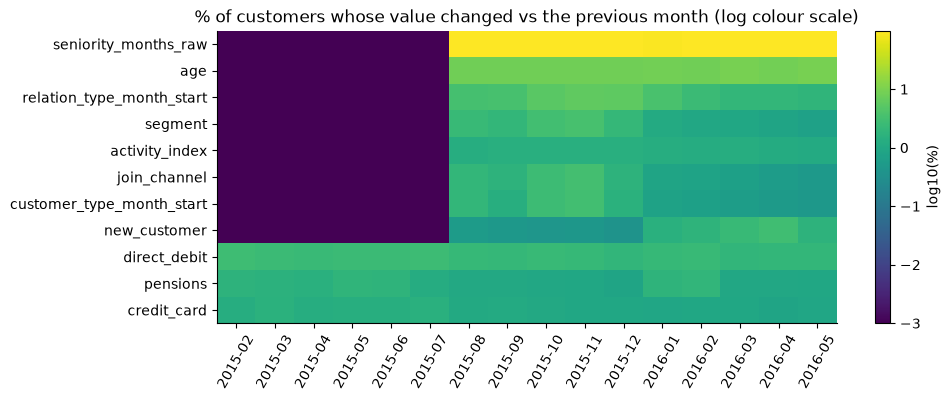

,2015-02,2015-03,2015-04,2015-05,2015-06,2015-07,2015-08,2015-09,2015-10,2015-11,2015-12,2016-01,2016-02,2016-03,2016-04,2016-05
seniority_months_raw,0.00,0.00,0.00,0.00,0.00,0.00,99.36,98.47,98.07,99.61,99.55,95.44,99.84,99.81,95.51,99.88
age,0.00,0.00,0.00,0.00,0.00,0.00,8.40,8.33,8.31,8.17,8.35,8.58,8.31,9.23,8.54,9.32
relation_type_month_start,0.00,0.00,0.00,0.00,0.00,0.00,3.29,3.51,5.32,6.04,5.81,3.68,2.57,2.07,2.01,1.84
segment,0.00,0.00,0.00,0.00,0.00,0.00,2.33,2.00,3.01,3.51,2.09,1.16,0.98,0.94,0.82,0.73
activity_index,0.00,0.00,0.00,0.00,0.00,0.00,1.32,1.42,1.41,1.39,1.41,1.30,1.26,1.30,1.19,1.15
join_channel,0.00,0.00,0.00,0.00,0.00,0.00,2.04,1.73,2.70,3.16,1.74,0.83,0.78,0.69,0.59,0.50
customer_type_month_start,0.00,0.00,0.00,0.00,0.00,0.00,2.00,1.38,2.64,3.00,1.58,0.77,0.69,0.62,0.53,0.45
new_customer,0.00,0.00,0.00,0.00,0.00,0.00,0.56,0.46,0.43,0.44,0.37,1.50,1.80,2.37,2.87,1.70
direct_debit,2.83,2.50,2.49,2.55,2.53,2.72,2.20,2.11,2.38,2.21,1.93,2.25,2.35,1.96,2.03,2.06
pensions,1.72,1.67,1.52,1.84,1.77,1.27,1.03,1.02,1.01,0.96,0.83,1.75,1.91,0.99,0.99,0.96


In [5]:
ch = sa.column_change_by_month()
cols = ["seniority_months_raw", "age", "relation_type_month_start", "segment", "activity_index", "join_channel",
        "customer_type_month_start", "new_customer", "direct_debit", "pensions", "credit_card"]
sub = ch.loc[[c for c in cols if c in ch.index]]
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(np.log10(sub.to_numpy() + 1e-3), aspect="auto", cmap="viridis")
ax.set_yticks(range(len(sub)), sub.index); ax.set_xticks(range(sub.shape[1]), sub.columns, rotation=60)
ax.set_title("% of customers whose value changed vs the previous month (log colour scale)")
fig.colorbar(im, label="log10(%)"); ax.grid(False); plt.show()
sub.round(2)

Profile columns (top 8 rows) change for 0.00% of customers from 2015-02 to 2015-07, then start moving in 2015-08.
Product columns (bottom 3 rows) keep changing by 1–3% a month throughout, so the data was still being collected —
only the profile was frozen. After 2015-08 the values look plausible: age changes for ~8.3% of customers a month,
i.e. about 1/12 have a birthday.

**3b. Seniority is recomputed from the contract date.** `seniority_months` stands still during the frozen months and
sometimes skips or repeats a month later on. `tenure_months` = calendar months between the snapshot date and
`first_contract_date` (a column that never changes for a customer). The chart below follows the customers who are present in all 17 months and whose two values agree in 2015-07 (about 89% of them). The value in the file stays flat until July while the real seniority keeps growing; the two meet in July. So the frozen value is the July value, copied back to earlier months.

raw seniority = recomputed tenure, from 2015-07 on: 88.8% of rows
customers in the chart: 539,892 (89% of those present all 17 months)
raw seniority, step vs the previous month from 2015-08 on: +1 96.97%, +2 1.53%, 0 1.45%, other 0.05%


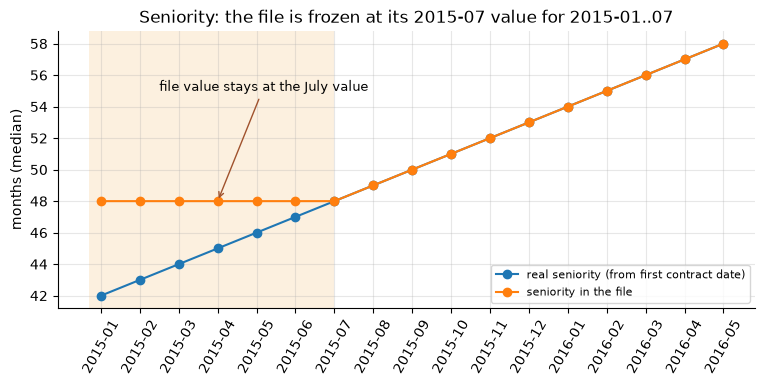

In [6]:
sv = sa.seniority_vs_tenure()
print(f"raw seniority = recomputed tenure, from 2015-07 on: {sv['share_equal_from_jul']:.1%} of rows")
print(f"customers in the chart: {sv['n_kept']:,} ({sv['share_kept']:.0%} of those present all 17 months)")
print("raw seniority, step vs the previous month from 2015-08 on: "
      + ", ".join(f"{k} {v:.2f}%" for k, v in sv["steps_from_jul"].items()))
med = sv["median"]
fig, ax = plt.subplots()
ax.plot(med.index, med.tenure_months, marker="o", label="real seniority (from first contract date)")
ax.plot(med.index, med.seniority_months_raw, marker="o", label="seniority in the file")
ax.axvspan(-0.3, 6, color="#f0ad4e", alpha=0.18, lw=0)
ax.annotate("file value stays at the July value", xy=(3, med.seniority_months_raw.iloc[3]), xytext=(1.5, 55),
            fontsize=9, arrowprops=dict(arrowstyle="->", color="#a0522d"))
ax.set_ylabel("months (median)"); ax.set_title("Seniority: the file is frozen at its 2015-07 value for 2015-01..07")
ax.legend(loc="lower right", fontsize=8); plt.xticks(rotation=60); plt.show()

**3c. `new_customer` sometimes switches 0 → 1, which contradicts its definition** ("registered in the last 6 months").
Most of these customers have been with the bank for years and their contract date does not change, so these are
**likely recording errors**. We added `is_new_6m` (tenure ≤ 5 months) instead of using the raw flag, and kept the raw
column unchanged.

In [7]:
tr = sa.column_transitions(["new_customer", "join_channel"])
nc = tr[tr.column == "new_customer"].set_index(["from", "to"])["count"]
print("new_customer transitions:\n", nc.to_string())
print(f"\nis_new_6m agrees with the raw flag on {sa.is_new_6m_agreement():.2%} of rows (months ≥ 2015-08)")

new_customer transitions:
 from  to
1     0     112689
0     1        906

is_new_6m agrees with the raw flag on 99.54% of rows (months ≥ 2015-08)


**3d. Apparent changes in `join_channel` are mostly missing values filled in a month later** for brand-new customers,
not customers switching channel. Left as they are (missing = "not recorded yet").

In [8]:
jc = tr[tr.column == "join_channel"].copy()
isnull = lambda v: v.isna() | v.astype(str).isin(["<null>", "nan", ""])
jc["kind"] = np.where(isnull(jc["from"]), "missing → value", np.where(isnull(jc["to"]), "value → missing", "channel → channel"))
k = jc.groupby("kind")["count"].sum().to_frame("transitions"); k["share %"] = (k.transitions / k.transitions.sum() * 100).round(1)
k

,transitions,share %
kind,,
channel → channel,2617,2.0
missing → value,125921,97.7
value → missing,341,0.3


Other fixes (in `pipeline/make_clean_parquet.py`): ages outside 2–110 set to missing (children's junior accounts and very old,
often deceased, customers are real); `"1"` vs `"1.0"` merged in `customer_type_month_start`; `spouse_of_employee`
(≈100% missing) dropped. Household income is missing for ~20% of customers and never changes for a customer, so it is
treated as a per-customer attribute (log-transformed in the features).

## 4. Target definition
Unit = (customer, month *t*) where the customer is also present at *t−1*. For each product, `new_<p>` = 1 iff the flag
is 0 at *t−1* and 1 at *t*. Drops are ignored; a product dropped and taken again later counts as a new add (a
"re-add"); a missing flag never counts as an add. Adds are concentrated in a handful of products, and many adds are
re-adds of something the customer held before — which is why "ever held this product" features help.

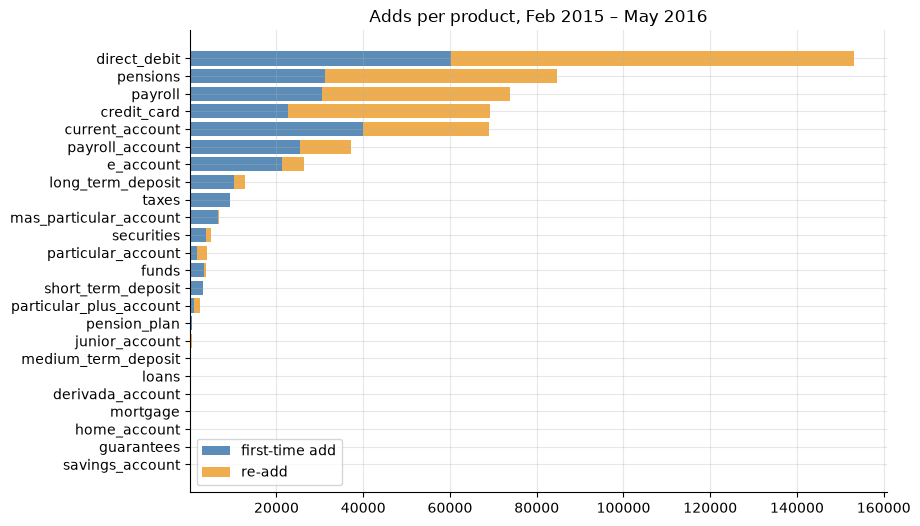

total adds 561,710; top-5 products = 80% of all adds


In [9]:
ap = adds_by_product.sort_values("adds")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ap.index, ap["adds"] - ap["re_adds"], color="#5b8db8", label="first-time add")
ax.barh(ap.index, ap["re_adds"], left=ap["adds"] - ap["re_adds"], color="#f0ad4e", label="re-add")
ax.set_title("Adds per product, Feb 2015 – May 2016"); ax.legend(); plt.show()
print(f"total adds {ap.adds.sum():,}; top-5 products = {ap.adds.nlargest(5).sum() / ap.adds.sum():.0%} of all adds")

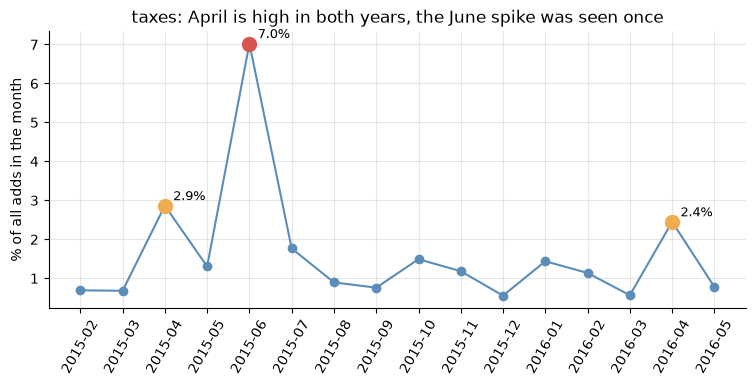

taxes share of adds: April 2015 2.9%, April 2016 2.4%, June 2015 7.0%, other months 1.0% on average


In [10]:
mix = sa.adds_mix_by_month(panel)
tx = mix["taxes"]
fig, ax = plt.subplots()
ax.plot(tx.index, tx.values, marker="o", color="#5b8db8")
for mo, col in [("2015-04", "#f0ad4e"), ("2016-04", "#f0ad4e"), ("2015-06", "#d9534f")]:
    ax.plot(mo, tx[mo], "o", ms=10, color=col)
    ax.annotate(f"{tx[mo]:.1f}%", (mo, tx[mo]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set_ylabel("% of all adds in the month"); ax.set_title("taxes: April is high in both years, the June spike was seen once")
plt.xticks(rotation=60); plt.show()
other = [x for x in tx.index if x not in ("2015-04", "2015-06", "2016-04")]
print(f"taxes share of adds: April 2015 {tx['2015-04']:.1f}%, April 2016 {tx['2016-04']:.1f}%, June 2015 {tx['2015-06']:.1f}%, "
      f"other months {tx[other].mean():.1f}% on average")

**June is different, and the test month is a June.** In June 2015, 5.3% of eligible customers added a product (the
highest of all 16 months), and `taxes` made up 7.0% of adds. The `taxes` season repeats in both years we have
(April is high in 2015 and in 2016), but the size of the June spike was seen only once, so we cannot tell whether
June 2016 will spike as much. The model sees June through `month_of_year` like any other month; we did not add
June-specific weighting or rules, because one June is too little to learn them from and our validation months
contain no June to check them.

## 5. Validation design and how big "noise" is
**Rolling-origin folds:** validate on target months 2016-02, 03, 04, 05; for each, train from scratch on all earlier
months. No random K-fold: the same customer appears in many months, and the future must not inform the past.
Model decisions use the 4-fold mean and **paired** per-fold differences.

Before reading any comparison it helps to know how large a difference has to be to mean anything:

In [11]:
pv = change_exp.pivot_table(index=["variant", "val_month"], columns="seed", values="MAP7")
seed_diff = (pv[1] - pv[2]).abs()
SEED_NOISE = seed_diff.mean()                                   # used as the grey band in §8
mean_diff = (pv[1] - pv[2]).groupby(level="variant").mean()
print(f"same model, different seed  : mean |diff| per fold {SEED_NOISE:.4f} (max {seed_diff.max():.4f}); "
      f"diff of the 4-fold mean: {mean_diff.abs().min():.4f}–{mean_diff.abs().max():.4f}")
print(f"same model, different month : std across the 4 folds {model_cmp.loc['std', 'lgbm_multiclass']:.4f}")
boot = sa.bootstrap_noise()       # resample the customers of each validation month (saved LightGBM scores)
print(f"same model, different customers (bootstrap within one month): sd {boot.mean():.4f} "
      f"({boot.min():.4f}–{boot.max():.4f} across the 4 months)")

same model, different seed  : mean |diff| per fold 0.0010 (max 0.0033); diff of the 4-fold mean: 0.0005–0.0010
same model, different month : std across the 4 folds 0.0063


same model, different customers (bootstrap within one month): sd 0.0014 (0.0013–0.0015 across the 4 months)


So a gain of about +0.001 is within seed noise unless it shows up consistently in paired comparisons across folds
**and** seeds. Most "improvements" below do not pass that bar.

*Note for later:* in these four feature variants seed 1 scored higher than seed 2 every time (by 0.0005–0.001 on the
4-fold mean). With only two seeds this may be chance; more seeds would tell.

## 6. Baselines
Simple rankings that give every customer the same order (minus products already held), plus an item-association rule
(the only baseline whose ranking depends on the products the customer already holds).
Any model must clearly beat these.

In [12]:
b = pd.concat([sa.popularity_baselines(panel), sa.association_rule(panel)])
b.groupby("model")[["MAP@7", "recall@7"]].mean().sort_values("MAP@7")

,MAP@7,recall@7
model,,
random,0.1242,0.3282
pop_last_month,0.5965,0.9577
pop_last_3,0.6323,0.9574
pop_all_time,0.6437,0.9561
add_rate_last_3,0.6463,0.9582
pop_same_month_last_year,0.6519,0.9541
item association rule,0.6727,0.9587


Recall@7 is already ~0.95 for popularity: the products people add are almost always somewhere in a 7-item list.
The gap between methods is about **order**, not coverage.

## 7. Features and training rows
Every feature uses information available **at the end of month t−1** only, built by the same function for train and
test (`pipeline/make_features.py`, `pipeline/make_profile_change.py`, `santander/final_features.py`).

In [13]:
fc = json.load(open(os.path.join(PROC, "feature_columns.json")))["features"]
pc = json.load(open(os.path.join(PROC, "profile_change_columns.json")))
def group(c):
    if c.endswith(tuple(f"_lag{i}" for i in range(1, 6))): return "product flags, lag 1–5"
    if c.startswith("ever_held_"): return "ever held <product>"
    if c in ("n_prev_products", "n_adds_last5", "n_drops_last5", "n_prior_months"): return "history counts"
    if c == "month_of_year": return "calendar"
    return "profile at t−1"
g = pd.Series([group(c) for c in fc]).value_counts()
g["profile lags t−2..t−5 (set B)"] = len(pc["B"])
g.to_frame("n features")

,n features
"product flags, lag 1–5",120
ever held <product>,24
profile at t−1,17
history counts,4
calendar,1
profile lags t−2..t−5 (set B),12


*The table shows the features at this point of the story: the 166 base features plus set B (last row, 12), which is tested and adopted in §8. The three sensitive columns (`sex`, `foreigner_index`, `residence_index`) are removed in §11 after the XAI check, so the final model uses 166 + 12 − 3 = **175** features. `n_prior_months` is replaced by its capped version (below), so the count does not change.*

**Training rows.** MAP@7 only scores customers who add something, so the model only needs to learn *which* product,
not *whether*. Training uses adder rows only, expanded to one row per added product (multiclass label), with no weights.

**A trade-off we accepted: capping `n_prior_months`.** This feature counts how many months the customer has appeared
in the data before *t*. For customers present since the start it equals the calendar month index, so it mostly encodes
*time*, not behaviour. In test, most customers have a value never seen in training:

In [14]:
ftr = pd.read_parquet(os.path.join(PROC, "features_train.parquet"), columns=["n_prior_months"])
fte = pd.read_parquet(os.path.join(PROC, "features_test.parquet"), columns=["n_prior_months"])
print(f"train max {ftr.n_prior_months.max()}, test share with value > train max: "
      f"{(fte.n_prior_months > ftr.n_prior_months.max()).mean():.0%}")
cap = change_exp[change_exp.variant.isin(["base", "cap"])].pivot_table(index=["seed", "val_month"], columns="variant", values="MAP7")
print(f"capping at 6: mean change {(cap['cap'] - cap['base']).mean():+.4f} "
      f"(worse in {(cap['cap'] < cap['base']).sum()}/{len(cap)} fold×seed pairs)")

train max 16, test share with value > train max: 65%
capping at 6: mean change -0.0012 (worse in 7/8 fold×seed pairs)


Capping at 6 costs about 0.001 on validation, measured. It was adopted anyway: the uncapped version asks the model to
extrapolate to an unseen value for most test customers, and how long the customer has been with the bank is still
available through `tenure_months`. Our guess for the validation cost is that the uncapped feature lets the model
recognise the time period — that is a hypothesis, not tested.

## 8. Experiment log — what was tried, what happened
Each row is a paired comparison against the reference used at the time (same folds, same seeds).
The shaded band is ± the mean per-fold seed-to-seed difference measured in §5.

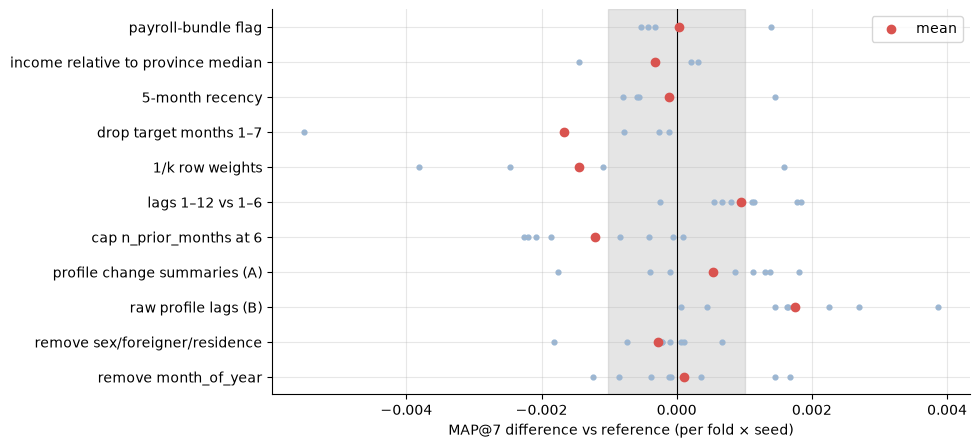

,mean_diff,better,pairs,decision
experiment,,,,
payroll-bundle flag,+0.0000,1/4,4,not adopted
income relative to province median,-0.0003,2/4,4,not adopted
5-month recency,-0.0001,1/4,4,not adopted
drop target months 1–7,-0.0017,0/4,4,not adopted
1/k row weights,-0.0014,1/4,4,not adopted
lags 1–12 vs 1–6,+0.0010,7/8,8,not adopted (null-pattern mismatch)
cap n_prior_months at 6,-0.0012,1/8,8,adopted (see §7)
profile change summaries (A),+0.0005,5/8,8,not adopted
raw profile lags (B),+0.0018,8/8,8,adopted


In [15]:
rows = []
def add(name, ref_df, ref_key, new_df, new_key, key="variant", seeds=(1,), decision=""):
    for s in seeds:
        r = ref_df[(ref_df[key] == ref_key) & (ref_df.get("seed", 1) == s)].set_index("val_month").MAP7
        n = new_df[(new_df[key] == new_key) & (new_df.get("seed", 1) == s)].set_index("val_month").MAP7
        for f in r.index.intersection(n.index):
            rows.append(dict(experiment=name, seed=s, fold=f, diff=n[f] - r[f], decision=decision))

fe = csv("models/feat_experiments.csv"); le = csv("models/lag_experiments.csv")
add("payroll-bundle flag", fe, "base", fe, "bundle", decision="not adopted")
add("income relative to province median", fe, "base", fe, "income", decision="not adopted")
add("5-month recency", fe, "base", fe, "recency", decision="not adopted")
add("drop target months 1–7", fe, "base", fe, "early8", decision="not adopted")
add("1/k row weights", fe, "base", fe, "weight1k", decision="not adopted")
add("lags 1–12 vs 1–6", le, "L6", le, "L12", key="set", seeds=(1, 2), decision="not adopted (null-pattern mismatch)")
add("cap n_prior_months at 6", change_exp, "base", change_exp, "cap", seeds=(1, 2), decision="adopted (see §7)")
add("profile change summaries (A)", change_exp, "cap", change_exp, "cap+A", seeds=(1, 2), decision="not adopted")
add("raw profile lags (B)", change_exp, "cap", change_exp, "cap+B", seeds=(1, 2), decision="adopted")

sens = csv("models/sensitive_ablation.csv").rename(columns={"MAP7_no_sensitive": "MAP7"}).assign(variant="no_sens")
add("remove sex/foreigner/residence", change_exp, "cap+B", sens, "no_sens", seeds=(1, 2), decision="adopted (see §11)")
mon = csv("models/month_ablation.csv").rename(columns={"MAP7_no_month": "MAP7"}).assign(variant="no_month")
add("remove month_of_year", sens, "no_sens", mon, "no_month", seeds=(1, 2), decision="kept (judgment call)")

ex = pd.DataFrame(rows)
summ = ex.groupby("experiment", sort=False).agg(mean_diff=("diff", "mean"), better=("diff", lambda x: f"{(x > 0).sum()}/{len(x)}"),
                                                 pairs=("diff", "size"), decision=("decision", "first"))
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(summ))[::-1]
ax.axvspan(-SEED_NOISE, SEED_NOISE, color="grey", alpha=0.2); ax.axvline(0, color="k", lw=0.8)
for yi, (name, grp) in zip(y, ex.groupby("experiment", sort=False)):
    ax.scatter(grp["diff"], np.full(len(grp), yi), s=12, color="#9bb7d4")
ax.scatter(summ.mean_diff, y, color="#d9534f", zorder=3, label="mean")
ax.set_yticks(y, summ.index); ax.set_xlabel("MAP@7 difference vs reference (per fold × seed)"); ax.legend(); plt.show()
summ.assign(mean_diff=summ.mean_diff.map("{:+.4f}".format))

Two notes for the reader:
- **Lags 1–12** looked slightly better but were not adopted: training rows from early months have most long lags
  missing, while test rows have them filled, so the gain may not transfer.
- **Up-weighting June 2015** to imitate the June 2016 target was deliberately *not* tried: it would tune the model to
  one specific month rather than improve it.

## 9. Model comparison (default settings)
Same folds and evaluation for all. **Caveat:** this table uses the earlier 166-feature set and mostly default
hyperparameters; the table at the end of this section compares models on the final 175 features.

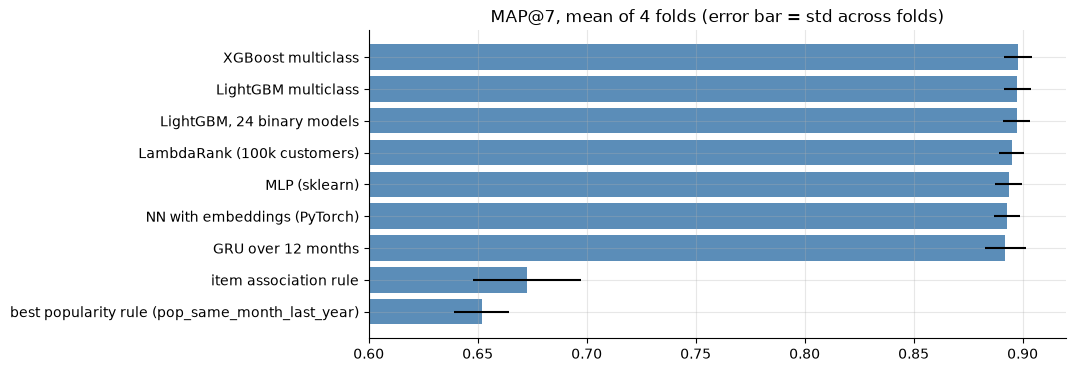

fold,mean,std
best popularity rule (pop_same_month_last_year),0.6519,0.0126
item association rule,0.6727,0.0249
GRU over 12 months,0.8920,0.0094
NN with embeddings (PyTorch),0.8927,0.0060
MLP (sklearn),0.8936,0.0060
LambdaRank (100k customers),0.8949,0.0059
"LightGBM, 24 binary models",0.8974,0.0062
LightGBM multiclass,0.8976,0.0063
XGBoost multiclass,0.8978,0.0066


In [16]:
names = {"lgbm_multiclass": "LightGBM multiclass", "xgb_multiclass": "XGBoost multiclass",
         "binary24_lgbm": "LightGBM, 24 binary models", "lambdarank_100k": "LambdaRank (100k customers)",
         "mlp_sklearn": "MLP (sklearn)", "nn_pytorch": "NN with embeddings (PyTorch)", "gru_pytorch": "GRU over 12 months"}
t9 = model_cmp.loc[["mean", "std"], list(names)].T.rename(index=names)
# baselines from §6, computed live: the best of the five popularity rules, and the item-association rule
bl = pd.concat([sa.popularity_baselines(panel), sa.association_rule(panel)]).groupby("model")["MAP@7"].agg(["mean", "std"])
best_pop = bl.drop(["random", "item association rule"])["mean"].idxmax()
t9.loc[f"best popularity rule ({best_pop})"] = bl.loc[best_pop]
t9.loc["item association rule"] = bl.loc["item association rule"]
t9 = t9.sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(t9.index, t9["mean"], xerr=t9["std"], color="#5b8db8"); ax.set_xlim(0.6, 0.92)
ax.set_title("MAP@7, mean of 4 folds (error bar = std across folds)"); plt.show()
t9

The popularity row is the best of the five popularity rules from §6, picked on these same four months, so it is
slightly optimistic. All learned models sit within ~0.006 of each other — about the month-to-month spread — so the
feature work, not the choice of algorithm, is what moved the score.

The table below checks this from the other side, on the **final 175 features**: a plain logistic regression
(`experiments/compare_extra.py`, one fixed setting) next to LightGBM, XGBoost and the PyTorch NN with their current settings.
It is clearly below the trees in every fold, but it already covers most of the distance from the baselines to the
trees.

In [17]:
from experiments.tune_summary import load as tload, summarise
FOLD_LABEL = {13: "2016-02", 14: "2016-03", 15: "2016-04", 16: "2016-05"}
MONTHS = list(FOLD_LABEL.values())
ext = {}
x = csv("models/extra_models.csv"); x = x[~x.smoke.astype(str).str.lower().eq("true")]
lr = x[x.model == "logreg"].set_index("fold").MAP7      # 'iter' = solver iterations here (differs per fold): not a checkpoint
if len(lr) == 4:
    ext["logistic regression"] = lr
# current settings of the three main families (= config 0 in the tuning files), seed 1, same 175 features and folds;
# rounds / epochs = the best point of the 4-fold mean curve
res, _, done, cfgs = tload(os.path.join(AO, "tuning"))
rank, _, _ = summarise(res, done, cfgs, seed=1)
for _, r in rank[rank.cfg == 0].iterrows():
    label = {"lgbm": "LightGBM", "xgb": "XGBoost", "nn": "NN (PyTorch)"}[r.model]
    ext[f"{label} ({r.best_iter} {'epochs' if r.model == 'nn' else 'rounds'})"] = pd.Series(
        {f: r[f"f{f}"] for f in FOLD_LABEL})
t9b = pd.DataFrame(ext).T.rename(columns=FOLD_LABEL)
t9b["mean"] = t9b[MONTHS].mean(axis=1)
ref = t9b.loc[[i for i in t9b.index if i.startswith("LightGBM")][0], MONTHS]
t9b["diff vs LightGBM"] = (t9b["mean"] - ref.mean()).map("{:+.4f}".format)
t9b["folds below LightGBM"] = [f"{int((t9b.loc[i, MONTHS] < ref).sum())}/4" for i in t9b.index]
t9b.sort_values("mean").round(4)

,2016-02,2016-03,2016-04,2016-05,mean,diff vs LightGBM,folds below LightGBM
logistic regression,0.8910,0.8898,0.8800,0.8946,0.8888,-0.0093,4/4
NN (PyTorch) (14 epochs),0.8972,0.8988,0.8894,0.9045,0.8975,-0.0006,2/4
LightGBM (75 rounds),0.8965,0.8985,0.8912,0.9062,0.8981,+0.0000,0/4
XGBoost (300 rounds),0.8958,0.8992,0.8920,0.9071,0.8985,+0.0004,1/4


## 10. Error analysis — where the model loses points
LightGBM multiclass on the **earlier 166-feature set** (default settings), pooled over the four validation months.
It predates profile set B, which was added partly because of what this analysis showed.

In [18]:
ea = sa.error_analysis()      # saved validation scores of the earlier 166-feature LightGBM, pooled over 4 folds
fr = ea["first_vs_readd"].rename(index={True: "first-time add", False: "re-add"})
display(fr[["events", "hit1", "hit7", "mean_rr"]])
bp = ea["by_product"].head(8).reset_index()
display(bp[["product", "adds_single", "AP", "hit1", "median_rank", "first_time_share", "share_of_AP_shortfall(single-add customers)"]])
bg = ea["by_group"]
st = change_exp.pivot_table(index=["seed", "val_month"], columns="variant", values="MAP7_stagnant")
print(f"stagnant customers, set B vs cap: {(st['cap+B'] - st['cap']).mean():+.4f} (better in {(st['cap+B'] > st['cap']).sum()}/{len(st)})")
bg[bg.dimension == "changes_last5(adds+drops)"].set_index("g")[["customers", "MAP7", "share_of_AP_shortfall"]].rename_axis("product changes in last 5 months")

,events,hit1,hit7,mean_rr
first_time,,,,
re-add,57698,0.9472,0.9998,0.9709
first-time add,32903,0.6599,0.9694,0.7680


,product,adds_single,AP,hit1,median_rank,first_time_share,share_of_AP_shortfall(single-add customers)
0,e_account,7983,0.7560,0.6312,1.0,0.8466,0.1604
1,credit_card,14872,0.8983,0.8405,1.0,0.1563,0.1245
2,direct_debit,37870,0.9666,0.9403,1.0,0.2854,0.1041
3,taxes,1611,0.2545,0.0397,5.0,0.9989,0.0989
4,mas_particular_account,2011,0.5590,0.3088,2.0,0.9564,0.0730
5,long_term_deposit,851,0.5028,0.2855,2.0,0.6161,0.0348
6,securities,660,0.3632,0.2530,5.0,0.6927,0.0346
7,current_account,14522,0.9730,0.9554,1.0,0.4561,0.0323


stagnant customers, set B vs cap: +0.0043 (better in 7/8)


,customers,MAP7,share_of_AP_shortfall
product changes in last 5 months,,,
0,33825,0.8132,0.5204
1,22134,0.9117,0.1610
2-3,37428,0.9384,0.1899
4+,25030,0.9375,0.1287


- The model is very good at **re-adds** (the product was held before) and much weaker on **first-time adds**.
- `taxes` is the clearest failure: added almost only for the first time, spiking in 2015-06, and ranked poorly.
- Customers with no product change in the last 5 months score clearly lower than everyone else. Profile set B
  (§8) was aimed at them and improved them (printed above, from `change_experiments.csv`).

## 11. Explainability (SHAP) and the sensitive-attribute decision
TreeSHAP on the final model (175 features) for 5,000 test customers, explaining each customer's #1 recommended product.
The chart and the comparison table use the same model and the same customers. The counterfactual test further down
uses version 1 of the model, which still had sex / foreigner / residence.

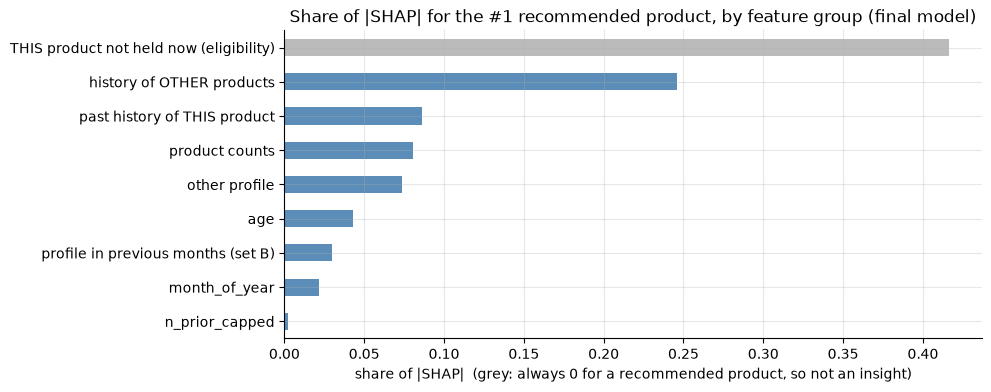

,lgbm,lgbm_s2,xgb
history of OTHER products,0.421,0.408,0.396
past history of THIS product,0.148,0.169,0.193
product counts,0.138,0.115,0.096
other profile,0.127,0.145,0.127
age,0.074,0.075,0.074
profile in previous months (set B),0.051,0.051,0.069
month_of_year,0.037,0.033,0.035
n_prior_capped,0.004,0.004,0.009


In [19]:
gs = sa.shap_group_shares()          # final model, 5,000 test customers (computed live from the saved model)
colors = ["#bbbbbb" if "eligibility" in g else "#5b8db8" for g in gs.index[::-1]]
ax = gs[::-1].plot.barh(color=colors, figsize=(9, 4),
                        title="Share of |SHAP| for the #1 recommended product, by feature group (final model)")
ax.set_xlabel("share of |SHAP|  (grey: always 0 for a recommended product, so not an insight)"); plt.show()
# same 5,000 customers, eligibility excluded: final LightGBM, the same LightGBM with seed 2, and XGBoost (xai_compare.py)
cg = csv("xai/compare_groups.csv", index_col=0).rename(index={"profile in previous months (B)": "profile in previous months (set B)"})
cg.round(3)

In [20]:
# counterfactual on version 1 (still had sex / foreigner / residence), 8,000 test customers:
# change ONE feature for everyone, predict again, count how often the recommendations change
sa.counterfactual_flips().round(1)

,#1 product changes %,top-7 set changes %
change (one feature only),,
sex H <-> V,8.4,15.5
foreigner N <-> S,6.0,18.5
age + 10 years,16.5,23.6
n_prior_capped -> 6,0.1,0.1


- Much of the "importance" is eligibility ("this product is not held now"), not insight.
- Group-level explanations agree across two LightGBM seeds and XGBoost; per-customer #1 features do not
  (credit is split among correlated features).

**Sensitive attributes.** Their SHAP share was small in version 1 (0.5% of |SHAP| for the #1 product), but the
counterfactual test above shows that flipping sex alone changes the #1 product for 8.4% of customers (foreigner flag: 6.0%), because the top candidates are
often close in probability. Removing the three columns changed MAP@7 by −0.0003 (4 folds × 2 seeds, §8), within noise.
**Decision:** removed. The measurement shows the removal is free; the choice not to let sex or nationality change a
financial-product recommendation is a judgment, stated as such. Removing direct use does not rule out proxies
(e.g. province).

**Stability.** The #1 recommendation changes with the random seed alone for ~15% of customers; 28% have a gap of less
than 0.05 between the #1 and #2 probabilities.

## 12. Final model and submission

In [21]:
fm = json.load(open(os.path.join(ROOT, "models", "final_lgbm_meta.json")))
print("features:", len(fm["features"]), "| rounds:", fm["rounds"], "| training rows:", f"{fm['train_rows']:,}",
      "| target months:", fm["train_target_months"])
print({k: v for k, v in fm["params"].items() if k not in ("verbose", "num_threads")})
sub = pd.read_csv(os.path.join(ROOT, "submission", "submission.csv"))
n = sub.iloc[:, 1].str.split().str.len()
print(f"\nsubmission rows {len(sub):,}; products per row: min {n.min()}, max {n.max()}")
sub.head()

features: 175 | rounds: 100 | training rows: 561,710 | target months: [1, 16]
{'objective': 'multiclass', 'num_class': 24, 'learning_rate': 0.1, 'num_leaves': 31, 'min_child_samples': 100, 'feature_fraction': 0.7, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l2': 5.0, 'max_bin': 127, 'seed': 1}



submission rows 929,615; products per row: min 7, max 7


,ncodpers,added_products
0,15889,ind_recibo_ult1 ind_ecue_fin_ult1 ind_reca_fin...
1,1170544,ind_recibo_ult1 ind_nomina_ult1 ind_nom_pens_u...
2,1170545,ind_recibo_ult1 ind_nom_pens_ult1 ind_nomina_u...
3,1170547,ind_nom_pens_ult1 ind_nomina_ult1 ind_cno_fin_...
4,1170548,ind_nomina_ult1 ind_nom_pens_ult1 ind_recibo_u...


`pipeline/check_submission.py` independently verifies the file against the raw data (row count, 7 products per row, none
already held in May 2016). Final 4-fold MAP@7 of this configuration: about 0.898.

**Kaggle score (late submission, after the competition closed).** The private leaderboard uses ~70% of the test
customers and gives the final ranking; the public one uses the other ~30%.

| submission | private | public |
|---|---|---|
| **final model** (175 features, sex / foreigner / residence removed) | **0.02740** | **0.02713** |
| same model with sex / foreigner / residence (178 features) | 0.02721 | 0.02688 |

For reference, the winning private score was 0.03140. Kaggle averages over *all* test customers (non-adders score
0), so these numbers are on a different scale from our 0.898. Removing the sensitive columns did not cost anything on
the test month either, consistent with §11; a single test month cannot show that the removal *helps*.

**How the winning solution differs** ([public write-up](https://www.kaggle.com/competitions/santander-product-recommendation/writeups/idle-speculation-1-solution)):
- **Ensemble:** about 20 models (12 neural nets and 8 GBMs) with several hundred features; this project uses one
  LightGBM model.
- **Month-specific scoring for seasonal products:** for example, `taxes` was scored as if the month were June 2015.
- **Leaderboard calibration:** product scores and ensemble weights were calibrated with public-leaderboard feedback.
  Here every setting was chosen on our own validation folds, so the Kaggle score stays an independent check.